## 0. Install Dependencies

In [2]:
%pip install --upgrade pip
# pytorch -> python 3.12 ;  pytorch 2.2.2 -> numpy 1.26.4 -> contourpy < 1.4
%pip install --force-reinstall "contourpy<1.4" "numpy==1.26.4"
%pip install torch torchvision matplotlib pandas

Note: you may need to restart the kernel to use updated packages.
  Using cached contourpy-1.3.3-cp312-cp312-macosx_10_13_x86_64.whl.metadata (5.5 kB)
  Using cached numpy-1.26.4-cp312-cp312-macosx_10_9_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-macosx_10_9_x86_64.whl (20.3 MB)
Using cached contourpy-1.3.3-cp312-cp312-macosx_10_13_x86_64.whl (293 kB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninstall: contourpy━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
    Found existing installation: contourpy 1.3.3━━ 0/2 [numpy]
    Uninstalling contourpy-1.3.3:━━━━━━━━━━━━━━━━━ 0/2 [numpy]
      Successfully uninstalled contourpy-1.3.3━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [contourpy]━ 1/2 [contourpy]
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 1. Load data and train CNN

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# create transform instance 
transform = transforms.ToTensor()

# Download train data if it isn't already under ./data directory
train_data = datasets.MNIST(
    "./data", train=True, download=True, transform=transform
)

# Download test data if it isn't already under ./data
test_data = datasets.MNIST(
    "./data", train=False, download=True, transform=transform
)

# create training data batch
train_loader = DataLoader(
    train_data, batch_size=128, shuffle=True
)
# create test data batch
test_loader = DataLoader(
    test_data, batch_size=256, shuffle=False
)

# Basic CNN
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        # with gradiant 32 -> 64
        # Layter 1 -> basic visual patterns (from gray-scale image)
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        # layter 2 -> complex visual patterns
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        
        # conbine features
        # fully connected layer y1 = w1ax1 + w12x2 + w13x3 from 64*7*7 to 128, gradient 24.5
        # input layter -> hidden layer
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        # Scores for 128 features to 10 digits 0-9
        # hidden layer -> output layer
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# move model parameters to device
model = CNN().to(device)
# adjust weights based on backpropogation calculation
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    # train in 5 epoches
    model.train()
    total_loss = 0

    
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        # clears prevous gradients
        optimizer.zero_grad()
        # make prediction and measure errors 
        loss = F.cross_entropy(model(x), y)
        # Calculates gradients
        loss.backward()
        # Updates the neural network's weights based on the calculated gradients.
        optimizer.step()

        total_loss += loss.item() * len(x)

    print(
        f"Epoch {epoch+1}: "
        f"loss={total_loss / len(train_data):.4f}" 
    )

model.eval()
correct = 0

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()

# Baseline accuracy
print(f"Clean accuracy: {correct / len(test_data):.2%}")
torch.save(model.state_dict(), "mnist_cnn.pt")


Epoch 1: loss=0.2555
Epoch 2: loss=0.0617
Epoch 3: loss=0.0426
Epoch 4: loss=0.0317
Epoch 5: loss=0.0247
Clean accuracy: 99.08%


The result  shows that more epochs reduces the loss, with the second epoch improves significantly(5 times).

## 2. FGSM, PGD, and MIFGSM

In [3]:

def gradient(model, x, y):
    x = x.detach().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    return torch.autograd.grad(loss, x)[0]

# restrict to eps variance
def project(x_adv, x_orig, eps):
    """Enforce L-infinity budget and valid pixels."""
    delta = (x_adv - x_orig).clamp(-eps, eps)
    return (x_orig + delta).clamp(0, 1).detach()


# 1. FGSM - Fast gradient sign method 
# [-eps: eps]
def fgsm(model, x, y, eps):
    grad = gradient(model, x, y)
    return project(x + eps * grad.sign(), x, eps)


# 2. I-FGSM / PGD
# [-0.2eps, 0.2 eps]
def pgd(model, x, y, eps, steps=20,
        alpha=None, random_start=True):

    alpha = eps / 5 if alpha is None else alpha

    if random_start:
        noise = torch.empty_like(x).uniform_(-eps, eps)
        x_adv = project(x + noise, x, eps)
    else:
        x_adv = x.clone().detach()

    for _ in range(steps):
        grad = gradient(model, x_adv, y)
        x_adv = project(
            x_adv + alpha * grad.sign(), x, eps
        )

    return x_adv


# 3. Momentum I-FGSM
def mifgsm(model, x, y, eps, steps=20,
           alpha=None, mu=1.0):

    alpha = eps / steps if alpha is None else alpha
    x_adv = x.clone().detach()
    momentum = torch.zeros_like(x)

    for _ in range(steps):
        grad = gradient(model, x_adv, y)

        # Per-image mean absolute gradient
        norm = grad.abs().mean(
            dim=(1, 2, 3), keepdim=True
        ).clamp_min(1e-12)

        momentum = mu * momentum + grad / norm

        x_adv = project(
            x_adv + alpha * momentum.sign(), x, eps
        )

    return x_adv


## 3. Run experiment

In [4]:

import pandas as pd

epsilons = [0.0, 0.05, 0.10, 0.20, 0.30]

def evaluate_attack(model, loader, attack_fn, eps):
    model.eval()

    total = 0
    clean_correct = 0
    adv_correct = 0
    successes = 0
    max_delta = 0.0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        with torch.no_grad():
            clean_pred = model(x).argmax(1)

        # Attack generation needs gradients
        if eps == 0:
            x_adv = x
        else:
            x_adv = attack_fn(model, x, y, eps)

        with torch.no_grad():
            adv_pred = model(x_adv).argmax(1)

        was_correct = clean_pred.eq(y)
        now_correct = adv_pred.eq(y)

        successes += (
            was_correct & ~now_correct
        ).sum().item()

        clean_correct += was_correct.sum().item()
        adv_correct += now_correct.sum().item()
        total += len(y)

        max_delta = max(
            max_delta,
            (x_adv - x).abs().max().item()
        )

    return {
        "Clean accuracy": clean_correct / total,
        "Adv accuracy": adv_correct / total,
        "ASR": successes / clean_correct,
        "Max perturbation": max_delta
    }


attacks = {
    "FGSM": lambda m, x, y, eps:
        fgsm(m, x, y, eps),

    "I-FGSM": lambda m, x, y, eps:
        pgd(m, x, y, eps, steps=20,
            alpha=eps/20, random_start=False),

    "PGD": lambda m, x, y, eps:
        pgd(m, x, y, eps, steps=20,
            alpha=eps/20, random_start=True),

    "MI-FGSM": lambda m, x, y, eps:
        mifgsm(m, x, y, eps, steps=20,
               alpha=eps/20, mu=1.0)
}

results = []

for eps in epsilons:
    for name, attack in attacks.items():

        metrics = evaluate_attack(
            model, test_loader, attack, eps
        )

        results.append({
            "Attack": name,
            "Epsilon": eps,
            **metrics
        })

df = pd.DataFrame(results)
print(df.to_string(index=False))


 Attack  Epsilon  Clean accuracy  Adv accuracy      ASR  Max perturbation
   FGSM     0.00          0.9908        0.9908 0.000000              0.00
 I-FGSM     0.00          0.9908        0.9908 0.000000              0.00
    PGD     0.00          0.9908        0.9908 0.000000              0.00
MI-FGSM     0.00          0.9908        0.9908 0.000000              0.00
   FGSM     0.05          0.9908        0.9633 0.027755              0.05
 I-FGSM     0.05          0.9908        0.9581 0.033004              0.05
    PGD     0.05          0.9908        0.9649 0.026140              0.05
MI-FGSM     0.05          0.9908        0.9583 0.032802              0.05
   FGSM     0.10          0.9908        0.8771 0.114756              0.10
 I-FGSM     0.10          0.9908        0.8111 0.181369              0.10
    PGD     0.10          0.9908        0.8486 0.143520              0.10
MI-FGSM     0.10          0.9908        0.8219 0.170468              0.10
   FGSM     0.20          0.9908      

### Result
The result shows that with an adversarial attack of epsilon 0.2, adv accuracy dropped significanlly. 
However, while FGSM is still able to reach a proxy of 0.4, the other two approaches quickly dropped to 0.1, which is almost a completely false. 
While at the same time, the higher the epsilon, the higher the attack successful rate. And FGSM always has a lower successful attack rate in all epsilon value.

## 4. Visualization

### Plot Epsilon - ASR

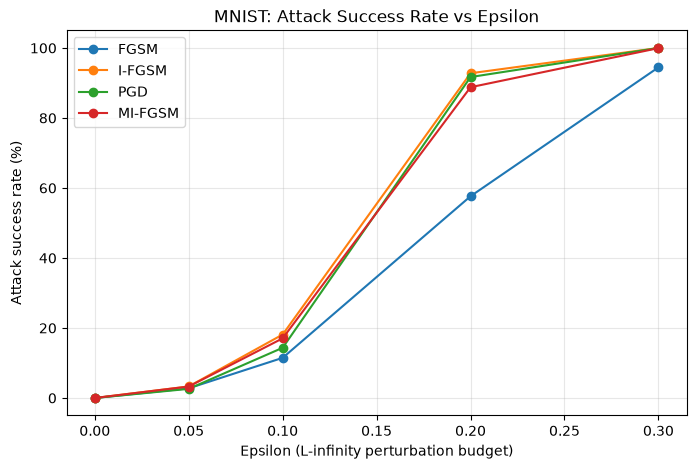

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for name in attacks:
    subset = df[df["Attack"] == name]
    plt.plot(
        subset["Epsilon"],
        subset["ASR"] * 100,
        marker="o",
        label=name
    )

plt.xlabel("Epsilon (L-infinity perturbation budget)")
plt.ylabel("Attack success rate (%)")
plt.title("MNIST: Attack Success Rate vs Epsilon")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Adversarial image VS Orignial

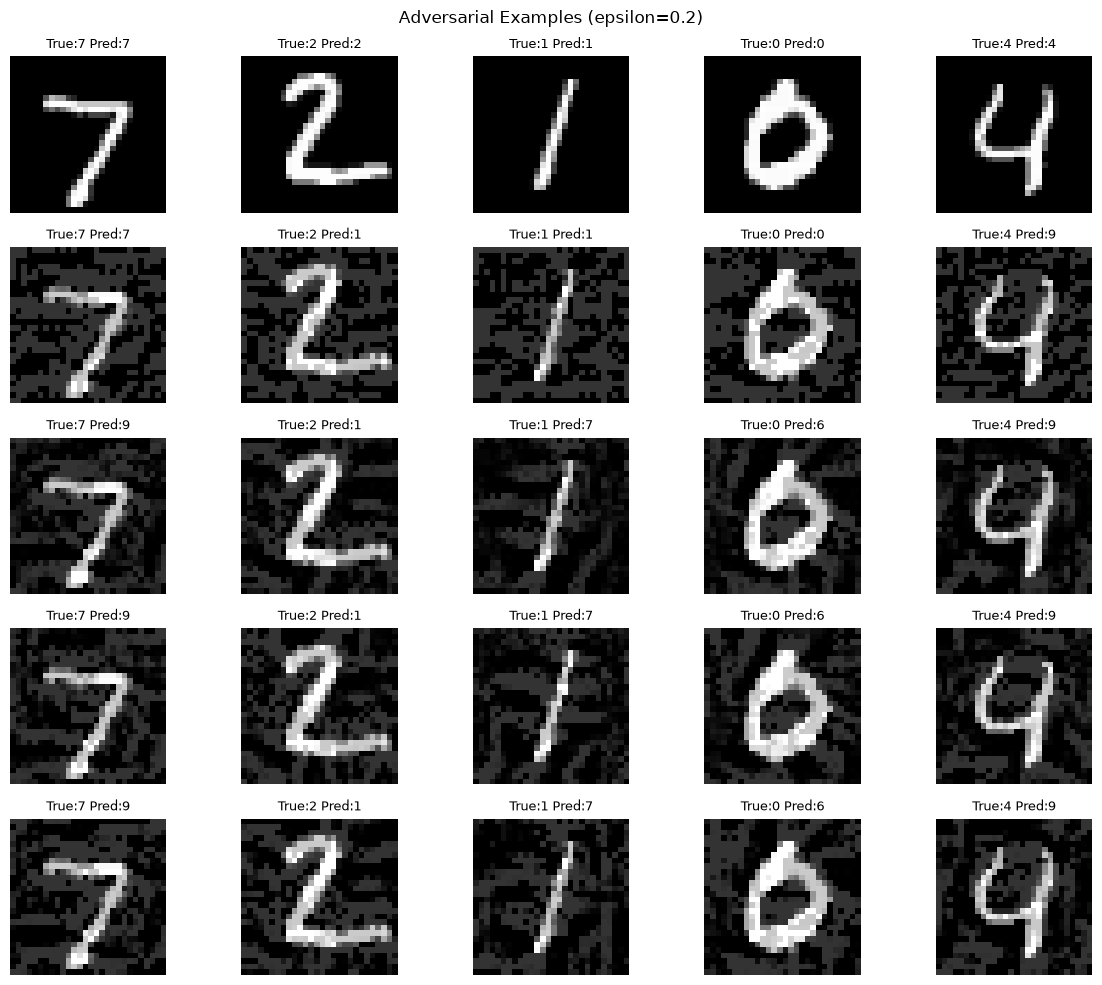

In [8]:

x, y = next(iter(test_loader))
x, y = x[:5].to(device), y[:5].to(device)

eps = 0.20
variants = {"Original": x}

for name, attack in attacks.items():
    variants[name] = attack(model, x, y, eps)

fig, axes = plt.subplots(
    len(variants), len(x), figsize=(12, 10)
)

for row, (name, images) in enumerate(variants.items()):
    with torch.no_grad():
        predictions = model(images).argmax(1)

    for col in range(len(x)):
        axes[row, col].imshow(
            images[col, 0].detach().cpu(),
            cmap="gray", vmin=0, vmax=1
        )
        axes[row, col].set_title(
            f"True:{y[col].item()} "
            f"Pred:{predictions[col].item()}",
            fontsize=9
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(name, rotation=90)

plt.suptitle(f"Adversarial Examples (epsilon={eps})")
plt.tight_layout()
plt.show()


### Visual comparison
From top to bottom are: Original, FGSM, I-FGSM, PGD, MI-FGSM
Visually , human eyes can hardly tell the differences from all the adversarial attackers, but neural networks give a very different result. 